In [15]:
import multiprocessing
multiprocessing.set_start_method('fork', force=True)

Part 1: Heart Disease

In [16]:
import pandas as pd

DATA_FILE = "cleveland.csv"

cleveland_data = pd.read_csv(DATA_FILE)

cleveland_data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [17]:
columns = cleveland_data.columns.tolist()
columns.remove('num')  # Remove the "num" column for the features list to choose from for target variables
print(columns)

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [18]:
# Give a heart disease true or false column based on the "num" column
cleveland_data['heart_disease'] = cleveland_data['num'] > 0
cleveland_data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,heart_disease
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,False
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,True
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,True
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,False
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,False


In [19]:
# Generate a few different permutations of headings to test k-nearest neighbors on, and see which one performs the best.
from itertools import combinations
from math import comb
import random


def generate_subsets(colums, n, attr, seed=None):
    # Remove duplicate values from the input while preserving their order.
    values = list(dict.fromkeys(colums))

    if not 0 <= attr <= len(values):
        raise ValueError("k must be between 0 and the number of unique values")

    total = comb(len(values), attr)
    if not 0 <= n <= total:
        raise ValueError(f"n must be between 0 and {total}")

    rng = random.Random(seed)
    subsets = list(combinations(values, attr))
    yield from rng.sample(subsets, n)

In [20]:
sets = list()
for subset in generate_subsets(columns, n=20, attr=4, seed=None):
    sets.append(subset)
    print(sets[-1])

('restecg', 'oldpeak', 'slope', 'ca')
('sex', 'restecg', 'ca', 'thal')
('age', 'trestbps', 'exang', 'thal')
('age', 'cp', 'thalach', 'thal')
('age', 'chol', 'restecg', 'oldpeak')
('age', 'cp', 'thalach', 'oldpeak')
('trestbps', 'thalach', 'exang', 'slope')
('fbs', 'restecg', 'exang', 'thal')
('age', 'sex', 'oldpeak', 'slope')
('sex', 'trestbps', 'restecg', 'exang')
('cp', 'chol', 'exang', 'oldpeak')
('sex', 'cp', 'chol', 'oldpeak')
('age', 'trestbps', 'chol', 'ca')
('sex', 'exang', 'oldpeak', 'slope')
('sex', 'chol', 'thalach', 'slope')
('sex', 'cp', 'chol', 'fbs')
('cp', 'trestbps', 'fbs', 'exang')
('age', 'sex', 'fbs', 'ca')
('restecg', 'thalach', 'oldpeak', 'ca')
('trestbps', 'chol', 'exang', 'oldpeak')


In [21]:
from collections.abc import Sequence
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# Each process gets its own copy of these values through the initializer.
_WORKER_DATA = None
_WORKER_Y = None
_WORKER_SPLITS = None
_WORKER_NEIGHBOR_VALUES = None


def _predict_knn(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_test: np.ndarray,
    n_neighbors: int,
) -> np.ndarray:
    """Predict binary labels using Euclidean-distance KNN."""
    distances = np.sum(
        (X_test[:, None, :] - X_train[None, :, :]) ** 2,
        axis=2,
    )
    nearest = np.argpartition(
        distances,
        kth=n_neighbors - 1,
        axis=1,
    )[:, :n_neighbors]

    predictions = []
    for neighbor_indices in nearest:
        votes = np.bincount(
            y_train[neighbor_indices],
            minlength=2,
        )
        # A tie is classified as 0 because np.argmax chooses the first max.
        predictions.append(int(np.argmax(votes)))

    return np.asarray(predictions)


def _init_knn_worker(data, y, split_indices, neighbor_values):
    """Initialize data shared by tasks running in each process."""
    global _WORKER_DATA
    global _WORKER_Y
    global _WORKER_SPLITS
    global _WORKER_NEIGHBOR_VALUES

    _WORKER_DATA = data
    _WORKER_Y = y
    _WORKER_SPLITS = split_indices
    _WORKER_NEIGHBOR_VALUES = neighbor_values


def _evaluate_subset_split(task):
    """Evaluate one feature subset on one train/test split."""
    subset, split_index = task
    split_seed, train_ids, test_ids = _WORKER_SPLITS[split_index]

    X = (
        _WORKER_DATA.loc[:, list(subset)]
        .apply(pd.to_numeric, errors="coerce")
        .to_numpy(dtype=float)
    )

    X_train = X[train_ids]
    X_test = X[test_ids]
    y_train = _WORKER_Y[train_ids]
    y_test = _WORKER_Y[test_ids]

    imputer = SimpleImputer(strategy="median")
    X_train = imputer.fit_transform(X_train)
    X_test = imputer.transform(X_test)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    rows = []

    for n_neighbors in _WORKER_NEIGHBOR_VALUES:
        predictions = _predict_knn(
            X_train,
            y_train,
            X_test,
            n_neighbors,
        )

        tn, fp, fn, tp = confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1],
        ).ravel()

        rows.append(
            {
                "attributes": subset,
                "n_neighbors": n_neighbors,
                "split_seed": split_seed,
                "precision": precision_score(
                    y_test,
                    predictions,
                    zero_division=0,
                ),
                "recall": recall_score(
                    y_test,
                    predictions,
                    zero_division=0,
                ),
                "f1": f1_score(
                    y_test,
                    predictions,
                    zero_division=0,
                ),
                "tn": tn,
                "fp": fp,
                "fn": fn,
                "tp": tp,
            }
        )

    return rows


def run_knn_on_subsets(
    data: pd.DataFrame,
    subsets: Sequence[tuple[str, ...]],
    target_column: str = "num",
    test_size: float = 0.2,
    seed: int | None = None,
    iterations: int = 10,
    neighbor_values: Sequence[int] = (1, 3, 5, 7, 9, 11, 13, 15),
    processes: int | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Run repeated train/test evaluations in parallel.

    processes=None uses ProcessPoolExecutor's default worker count.

    Returns:
        runs: One row per model per split, with split seed, metrics,
              and confusion-matrix counts.
        summary: Mean precision, recall, and F1, plus summed
                 confusion-matrix counts for each model.
    """
    if iterations < 1:
        raise ValueError("iterations must be at least 1")
    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")
    if not subsets:
        raise ValueError("subsets must contain at least one feature subset")
    if not neighbor_values or any(k < 1 for k in neighbor_values):
        raise ValueError("neighbor_values must contain positive integers")
    if processes is not None and processes < 1:
        raise ValueError("processes must be at least 1 or None")

    master_seed = (
        int(seed)
        if seed is not None
        else int(np.random.SeedSequence().generate_state(1)[0])
    )
    rng = np.random.default_rng(master_seed)
    split_seeds = rng.integers(
        0,
        np.iinfo(np.int32).max,
        size=iterations,
    )

    # Convert Cleveland's num values to binary: 0 versus greater than 0.
    target = pd.to_numeric(data[target_column], errors="coerce")
    valid_rows = target.notna()
    y = (target.loc[valid_rows] > 0).astype(int).to_numpy()
    data = data.loc[valid_rows]

    if set(np.unique(y)) != {0, 1}:
        raise ValueError(
            "The usable target data must contain both classes 0 and 1"
        )

    normalized_subsets = []
    for subset in subsets:
        subset = tuple(subset)

        if not subset:
            raise ValueError("Feature subsets cannot be empty")
        if len(set(subset)) != len(subset):
            raise ValueError(f"Subset contains duplicate columns: {subset}")
        if target_column in subset:
            raise ValueError("The target column cannot also be a feature")

        missing = set(subset) - set(data.columns)
        if missing:
            raise ValueError(
                f"Columns not found in data: {sorted(missing)}"
            )

        normalized_subsets.append(subset)

    row_ids = np.arange(len(data))
    split_indices = []

    # Generate each split once and reuse it for every model.
    for split_seed in split_seeds:
        train_ids, test_ids = train_test_split(
            row_ids,
            test_size=test_size,
            random_state=int(split_seed),
            stratify=y,
        )
        split_indices.append(
            (int(split_seed), train_ids, test_ids)
        )

    largest_train_set = min(
        len(train_ids)
        for _, train_ids, _ in split_indices
    )
    if any(k > largest_train_set for k in neighbor_values):
        raise ValueError(
            "Every n_neighbors value must be no larger than the "
            f"smallest training set ({largest_train_set} rows)"
        )

    tasks = [
        (subset, split_index)
        for subset in normalized_subsets
        for split_index in range(iterations)
    ]

    rows = []
    with ProcessPoolExecutor(
        max_workers=processes,
        initializer=_init_knn_worker,
        initargs=(
            data,
            y,
            split_indices,
            tuple(neighbor_values),
        ),
    ) as executor:
        for task_rows in executor.map(_evaluate_subset_split, tasks):
            rows.extend(task_rows)

    runs = pd.DataFrame(rows)
    runs.attrs["master_seed"] = master_seed

    summary = (
        runs.groupby(
            ["attributes", "n_neighbors"],
            as_index=False,
            sort=False,
        )
        .agg(
            mean_precision=("precision", "mean"),
            mean_recall=("recall", "mean"),
            mean_f1=("f1", "mean"),
            tn=("tn", "sum"),
            fp=("fp", "sum"),
            fn=("fn", "sum"),
            tp=("tp", "sum"),
        )
        .sort_values("mean_f1", ascending=False)
        .reset_index(drop=True)
    )

    return runs, summary

In [22]:
# The target column is "num"; do not include it in the feature subsets.
feature_columns = [
    column for column in cleveland_data.columns
    if column != "num" and column != "heart_disease"
]

print(feature_columns)

subsets = list(combinations(feature_columns, 3))

runs, summary = run_knn_on_subsets(
    data=cleveland_data,
    subsets=subsets,
    target_column="heart_disease",
    test_size=0.2,
    seed=None,
    iterations=10,
    neighbor_values=(1, 3, 5, 7, 9, 11),
)

print("Master seed:", runs.attrs["master_seed"])
print(summary.head(20))

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Master seed: 2981923050
               attributes  n_neighbors  mean_precision  mean_recall   mean_f1  \
0          (cp, ca, thal)            9        0.823816     0.778571  0.799073   
1          (cp, ca, thal)           11        0.820764     0.775000  0.795355   
2         (cp, exang, ca)            5        0.820372     0.771429  0.793726   
3          (cp, ca, thal)            7        0.815114     0.778571  0.792927   
4         (sex, ca, thal)           11        0.783491     0.803571  0.791039   
5         (cp, exang, ca)           11        0.834983     0.757143  0.789571   
6          (cp, ca, thal)            5        0.816986     0.767857  0.787819   
7         (sex, ca, thal)            5        0.781812     0.792857  0.783859   
8         (cp, exang, ca)            9        0.825083     0.750000  0.781244   
9         (sex, ca, thal)            7        0.81147

In [28]:
# Just adding this because I think we need a cleaner report of the results

# Filter the 'runs' dataframe to show the 10 individual iterations for our best model
best_attributes = ('cp', 'ca', 'thal')
best_k = 9

best_model_runs = runs[(runs['attributes'] == best_attributes) & (runs['n_neighbors'] == best_k)]

# Display just the metrics the professor asked for
print(f"10 Cross-Validation Scores for K={best_k} using {best_attributes}:")
display(best_model_runs[['precision', 'recall', 'f1']])

10 Cross-Validation Scores for K=9 using ('cp', 'ca', 'thal'):


,precision,recall,f1
9904,0.689655,0.714286,0.701754
9910,0.785714,0.785714,0.785714
9916,0.869565,0.714286,0.784314
9922,0.958333,0.821429,0.884615
9928,0.821429,0.821429,0.821429
9934,0.840000,0.750000,0.792453
9940,0.777778,0.750000,0.763636
9946,0.827586,0.857143,0.842105
9952,0.875000,0.750000,0.807692
9958,0.793103,0.821429,0.807018


In [23]:
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from sklearn.neighbors import KNeighborsRegressor
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [24]:
df = pd.read_csv('boardgames_ranks.csv')
df.head()

,id,name,yearpublished,rank,bayesaverage,average,usersrated,is_expansion,abstracts_rank,cgs_rank,childrensgames_rank,familygames_rank,partygames_rank,strategygames_rank,thematic_rank,wargames_rank
0,224517,Brass: Birmingham,2018,1,8.39022,8.55904,60513,0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN
1,342942,Ark Nova,2021,2,8.35515,8.53855,63479,0,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN
2,161936,Pandemic Legacy: Season 1,2015,3,8.34261,8.49972,57904,0,NaN,NaN,NaN,NaN,NaN,3.0,1.0,NaN
3,174430,Gloomhaven,2017,4,8.28935,8.53111,67835,0,NaN,NaN,NaN,NaN,NaN,5.0,2.0,NaN
4,397598,Dune: Imperium – Uprising,2023,5,8.26913,8.69975,20546,0,NaN,NaN,NaN,NaN,NaN,4.0,NaN,NaN


In [25]:
baseGames = df[df['is_expansion'] == 0]
# 1. Define our features (X) and target variable (y)
feature_columns = [col for col in baseGames.columns if col.endswith('_rank')]
# Fill missing ranks with a high number to indicate they are unranked in that category
X = baseGames[feature_columns].fillna(10000000)
y = baseGames['rank']

# 2. Initialize and fit the model with exactly 10 neighbors
knn_reg = KNeighborsRegressor(n_neighbors=10, metric='euclidean')
knn_reg.fit(X, y)

# 3. Define the estimation function
def estimate_game_rank(game_name):
    # Find the index of the requested game
    if game_name not in baseGames['name'].values:
        return "Game not found in dataset."
        
    game_idx = baseGames[baseGames['name'] == game_name].index[0]
    
    # Extract the category rank features for this specific game
    game_features = X.loc[[game_idx]]
    
    # Predict the overall rank using the trained model
    estimated_rank = knn_reg.predict(game_features)[0]
    actual_rank = baseGames.loc[game_idx, 'rank']
    
    return {
        'Game': game_name,
        'Estimated Rank': int(round(estimated_rank)),
        'Actual Rank': actual_rank
    }

# Example usage
print(estimate_game_rank('Brass: Birmingham'))

{'Game': 'Brass: Birmingham', 'Estimated Rank': 10, 'Actual Rank': np.int64(1)}


Finished K=1
Finished K=3
Finished K=5
Finished K=7
Finished K=9
Finished K=11
Finished K=13
Finished K=15
Finished K=17
Finished K=19
Finished K=21
Finished K=23
Finished K=25
Finished K=27
Finished K=29


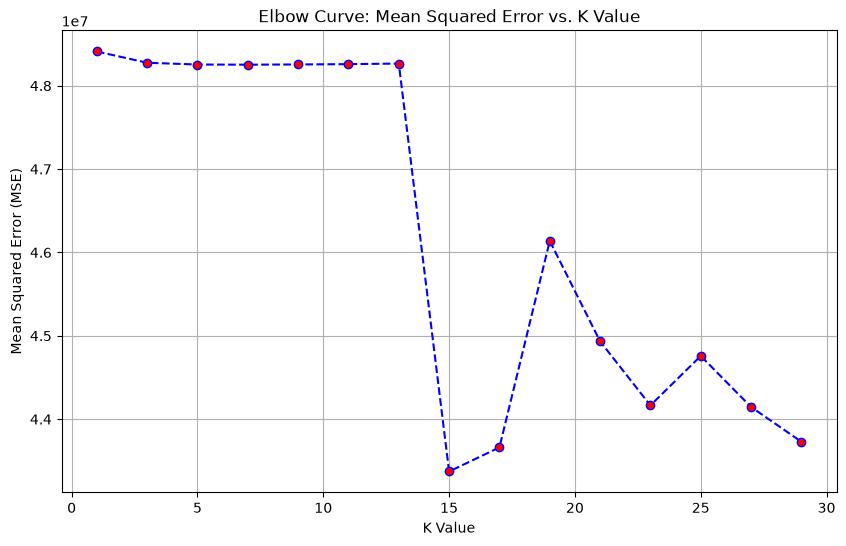

In [26]:
# 1. Split your data into training and testing sets so you can evaluate performance
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

error_rates = []
# Test fewer K values, stepping by 2 (e.g., 1, 3, 5, 7...) to cut the workload in half
k_values = range(1, 30, 2) 

for k in k_values:
    # n_jobs=-1 tells your computer to use all CPU cores at once
    knn = KNeighborsRegressor(n_neighbors=k, metric='euclidean', n_jobs=-1)
    knn.fit(X_train, y_train)
    pred_i = knn.predict(X_test)
    
    mse = mean_squared_error(y_test, pred_i)
    error_rates.append(mse)
    
    # Optional: Add a print statement so you can see it working!
    print(f"Finished K={k}")

# 3. Plot the Elbow Curve
plt.figure(figsize=(10, 6))
plt.plot(k_values, error_rates, color='blue', linestyle='dashed', marker='o', markerfacecolor='red', markersize=6)
plt.title('Elbow Curve: Mean Squared Error vs. K Value')
plt.xlabel('K Value')
plt.ylabel('Mean Squared Error (MSE)')
plt.grid(True)
plt.show()

In [27]:
# --- Part 2: Final Optimized Model ---

optimal_k = 13
print(f"Training optimized KNN model with K={optimal_k}...\n")

# 1. Initialize the model with our optimal K
final_knn = KNeighborsRegressor(n_neighbors=optimal_k, metric='euclidean', n_jobs=-1)

# 2. Fit on the training data first to show the final Test Error
final_knn.fit(X_train, y_train)
test_predictions = final_knn.predict(X_test)
final_mse = mean_squared_error(y_test, test_predictions)
print(f"Performance Metrics for K={optimal_k}:")
print(f"Mean Squared Error (MSE): {final_mse:.2f}")

# 3. Retrain on the ENTIRE dataset (X, y) so our estimator has maximum data to pull from
final_knn.fit(X, y)

# 4. Updated estimation function using the new final_knn model
def estimate_game_rank_optimized(game_name):
    if game_name not in baseGames['name'].values:
        return "Game not found in dataset."
        
    # Find index and extract features
    game_idx = baseGames[baseGames['name'] == game_name].index[0]
    game_features = X.loc[[game_idx]]
    
    # Predict with the k=13 model
    estimated_rank = final_knn.predict(game_features)[0]
    actual_rank = baseGames.loc[game_idx, 'rank']
    
    return {
        'Game': game_name, 
        'Estimated Rank': int(round(estimated_rank)), 
        'Actual Rank': actual_rank
    }

# Let's test it out with our new optimized model!
print("\nPrediction using Optimized Model:")
print(estimate_game_rank_optimized('Brass: Birmingham'))
print(estimate_game_rank_optimized('Agricola'))
print(estimate_game_rank_optimized('Wingspan'))
print(estimate_game_rank_optimized('Cthulhu: Death May Die'))

Training optimized KNN model with K=13...

Performance Metrics for K=13:
Mean Squared Error (MSE): 48265572.32

Prediction using Optimized Model:
{'Game': 'Brass: Birmingham', 'Estimated Rank': 12, 'Actual Rank': np.int64(1)}
{'Game': 'Agricola', 'Estimated Rank': 83, 'Actual Rank': np.int64(66)}
{'Game': 'Wingspan', 'Estimated Rank': 143, 'Actual Rank': np.int64(38)}
{'Game': 'Cthulhu: Death May Die', 'Estimated Rank': 83, 'Actual Rank': np.int64(55)}


In [48]:
import random

# 1. The specific games you want to highlight
target_games = [
    'Brass: Birmingham', 
    'Agricola', 
    'Cthulhu: Death May Die',
    'Clank!: Catacombs',
    'Obsession',
    'The Crew: Mission Deep Sea',
    'Harmonies',
    'Pandemic Legacy: Season 2',
    'Pandemic',
    'Flip 7',
    'Wingspan'
]

# 2. Grab 5 random games from the top 150 (excluding the ones we already picked)
top_150 = baseGames[(baseGames['rank'] <= 150) & (baseGames['rank'] > 0) & (~baseGames['name'].isin(target_games))]
random_top_games = random.sample(top_150['name'].tolist(), 5)

# Combine our lists
games_to_test = target_games # + random_top_games

# 3. Loop through the games and collect the results
results_list = []
for game in games_to_test:
    res = estimate_game_rank_optimized(game)
    
    # Ensure the game was found before processing
    if isinstance(res, dict): 
        # Calculate how far off the prediction was
        res['Off By'] = abs(res['Estimated Rank'] - res['Actual Rank'])
        results_list.append(res)

# 4. Convert the list of dictionaries into a Pandas DataFrame
results_df = pd.DataFrame(results_list)

# Sort the table by the Actual Rank so it reads nicely top-to-bottom
results_df = results_df.sort_values('Actual Rank').reset_index(drop=True)

# 5. Display the beautiful table! (Using display() instead of print() in Jupyter makes it format as HTML)
display(results_df)

,Game,Estimated Rank,Actual Rank,Off By
0,Brass: Birmingham,12,1,11
1,Wingspan,143,38,105
2,The Crew: Mission Deep Sea,143,45,98
3,Clank!: Catacombs,47,46,1
4,Harmonies,357,51,306
5,Cthulhu: Death May Die,83,55,28
6,Agricola,83,66,17
7,Obsession,61,67,6
8,Pandemic Legacy: Season 2,61,74,13
9,Pandemic,237,175,62
